# Honeypot Logs ML Model

This notebook builds a machine learning model to predict attack types based on the engineered features from honeypot logs.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from google.colab import drive

## 1. Data Preparation

Load the engineered dataset and prepare it for modeling.

In [ ]:
# Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# Load the engineered data
engineered_data_path = "/content/drive/My Drive/synthetic_logs/engineered_data.csv"
df = pd.read_csv(engineered_data_path)

Mounted at /content/drive


## 2. Train-Test Split

Split the data into training and testing sets to evaluate our model's performance.

In [ ]:
# Verify if 'attack_type' column exists, if not create it from 'signature'
if 'attack_type' not in df.columns:
    df['attack_type'] = df['signature'].apply(lambda x: x.split('|')[0])

# Display the first few rows of the dataset
df.head()


,timestamp,src,direction,protocol,ids_type,vendor_product,type,app,dest,dest_port,...,severity,dionaea_action,distance,hour,day_of_week,month,session_id,burst_size,attack_frequency,attack_type
0,2024-02-10 03:08:53.699888,192.168.1.1,inbound,0,network,Amun,amun.events,amun,10.0.2.16,106,...,high,NaN,5585.786795,3,5,2,274,7,1170,Brute Force
1,2024-02-10 03:09:14.699888,192.168.1.1,inbound,0,network,Amun,amun.events,amun,10.0.2.16,106,...,high,NaN,5585.786795,3,5,2,274,7,1170,Brute Force
2,2024-02-10 03:09:22.699888,192.168.1.1,inbound,0,network,Amun,amun.events,amun,10.0.2.16,3415,...,high,NaN,5585.786795,3,5,2,274,7,1170,Brute Force
3,2024-02-10 03:09:51.699888,192.168.1.1,inbound,0,network,Amun,amun.events,amun,10.0.2.16,469,...,low,NaN,5585.786795,3,5,2,274,7,1170,Brute Force
4,2024-02-10 03:09:53.699888,192.168.1.1,inbound,0,network,Amun,amun.events,amun,10.0.2.16,8106,...,medium,NaN,5585.786795,3,5,2,274,7,1170,Brute Force


In [ ]:
# Convert categorical variables to numeric using one-hot encoding
df_encoded = pd.get_dummies(df, columns=['src', 'direction', 'protocol', 'ids_type', 'vendor_product', 'type', 'app', 'transport', 'severity'])

# Ensure all columns are numeric
df_encoded = df_encoded.apply(pd.to_numeric, errors='coerce').fillna(0)

# Define features and target variable
features = df_encoded.drop(columns=['timestamp', 'signature', 'dest', 'sensor', 'attack_type'])  # Drop non-relevant columns
target = df['attack_type']

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

# Standardize the feature data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## 3. Model Selection and Training

Train different ML models to see which performs best. We'll start with a RandomForestClassifier.

In [ ]:
# Train a RandomForestClassifier
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = model.predict(X_test_scaled)

## 4. Evaluation

Evaluate the performance of the trained models.

In [ ]:
# Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nAccuracy Score:")
print(accuracy_score(y_test, y_pred))

Confusion Matrix:
[[326   0   0   0   0   0]
 [  0 327   0   0   6   0]
 [  0   0   1   0   0   0]
 [  0   0   0  67   0   0]
 [  0   0   0   0 288   0]
 [  0   0   0   0   0 332]]

Classification Report:
                precision    recall  f1-score   support

   Brute Force       1.00      1.00      1.00       326
          DDoS       1.00      0.98      0.99       333
Normal Traffic       1.00      1.00      1.00         1
      Phishing       1.00      1.00      1.00        67
    Ransomware       0.98      1.00      0.99       288
Reconnaissance       1.00      1.00      1.00       332

      accuracy                           1.00      1347
     macro avg       1.00      1.00      1.00      1347
  weighted avg       1.00      1.00      1.00      1347


Accuracy Score:
0.9955456570155902


## 5. Feature Importance

Visualize the feature importance to understand which features contribute the most to the model.

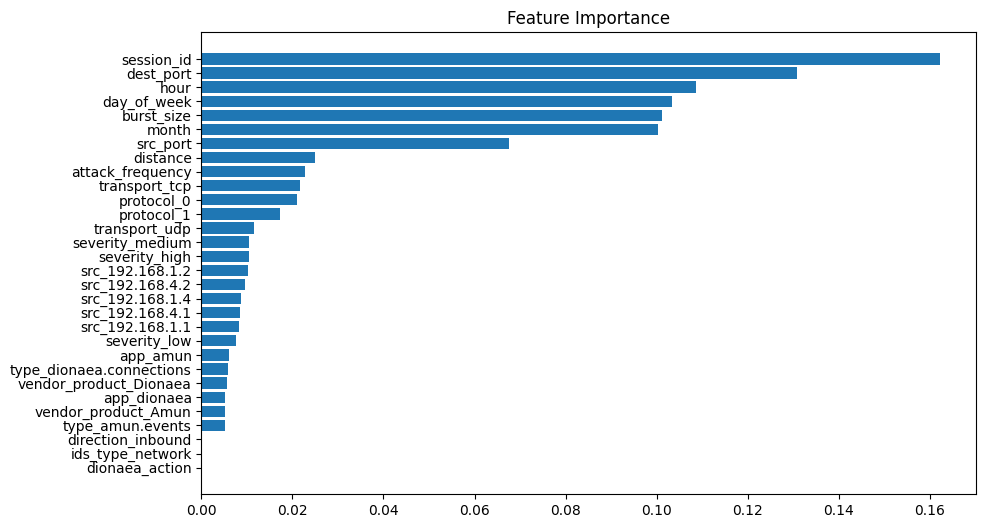

In [ ]:
# Plot feature importance
feature_importance = model.feature_importances_
sorted_idx = np.argsort(feature_importance)
plt.figure(figsize=(10, 6))
plt.barh(range(len(sorted_idx)), feature_importance[sorted_idx], align='center')
plt.yticks(range(len(sorted_idx)), np.array(features.columns)[sorted_idx])
plt.title('Feature Importance')
plt.show()

## 6. Prediction

Use the trained model to make predictions for today's data.

In [ ]:
# Predict today's attacks
df['timestamp'] = pd.to_datetime(df['timestamp'])
todays_data = df[df['timestamp'].dt.date == pd.to_datetime('today').date()]
todays_features = todays_data.drop(columns=['timestamp', 'signature', 'dest', 'sensor', 'attack_type'])
todays_features_encoded = pd.get_dummies(todays_features).reindex(columns=features.columns, fill_value=0)
todays_features_scaled = scaler.transform(todays_features_encoded)

# Predict attack types for today's data
todays_data['predicted_attack_type'] = model.predict(todays_features_scaled)

# Display the predictions
print(todays_data[['timestamp', 'src', 'predicted_attack_type']])

                      timestamp          src predicted_attack_type
2236 2024-08-08 03:18:33.699888  192.168.1.1           Brute Force
2237 2024-08-08 03:18:39.699888  192.168.1.1           Brute Force
2238 2024-08-08 04:15:35.699888  192.168.1.1              Phishing
2239 2024-08-08 04:15:44.699888  192.168.1.1              Phishing
2240 2024-08-08 04:15:45.699888  192.168.1.1              Phishing
2241 2024-08-08 04:15:58.699888  192.168.1.1              Phishing
2242 2024-08-08 04:16:00.699888  192.168.1.1              Phishing
2243 2024-08-08 09:45:19.699888  192.168.1.1        Reconnaissance
2244 2024-08-08 09:45:46.699888  192.168.1.1        Reconnaissance
4481 2024-08-08 03:18:33.699888  192.168.1.1           Brute Force
4482 2024-08-08 03:18:39.699888  192.168.1.1           Brute Force
4483 2024-08-08 04:15:35.699888  192.168.1.1              Phishing
4484 2024-08-08 04:15:44.699888  192.168.1.1              Phishing
4485 2024-08-08 04:15:45.699888  192.168.1.1              Phis

<ipython-input-19-ebba46479cdb>:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  todays_data['predicted_attack_type'] = model.predict(todays_features_scaled)
